<a href="https://colab.research.google.com/github/Dan2222001/CS470-image-quality-project/blob/main/01_display_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###Imports and Google Drive Setup

To get this to work, follow these steps:
1. Open your Google Drive (Both your personal and university accounts should have the files)
2. Find the "vizwiz" folder in the "Shared with me" tab
3. Right click the vizwiz folder and press "Organize", then "Add Shortcut"
4. Select "My Drive" and add it as a shortcut

The first code block should say: "Folder exists: True" if you did it right.

In [ ]:
# Imports
import json
from pathlib import Path
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd

from google.colab import drive

# Opening Folder From Drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder exists: True
test.json
train.json
val.json


###Testing Google Drive Connection with Opening Annotations - This part is mainly just seeing what the data is like and how to display it

In [ ]:
folder = Path("/content/drive/MyDrive/vizwiz/annotations")
print("Folder exists:", folder.exists())

#Printing files in the annoations folder
if folder.exists():
    for file in folder.iterdir():
        print(file.name)

#Load a dataset and print some data
with open(folder / "train.json", "r") as f:
    train_data = json.load(f)

print("Number of images:", len(train_data))
print("First annotation:", train_data[0])

Folder exists: True
test.json
train.json
val.json
Number of images: 23431
First annotation: {'flaws': {'FRM': 1, 'BLR': 5, 'DRK': 0, 'BRT': 3, 'OBS': 0, 'OTH': 0, 'NON': 0, 'ROT': 0}, 'image': 'VizWiz_train_00022585.jpg', 'unrecognizable': 4}


0 votes: 15751 images
1 votes: 4122 images
2 votes: 1424 images
3 votes: 878 images
4 votes: 725 images
5 votes: 531 images


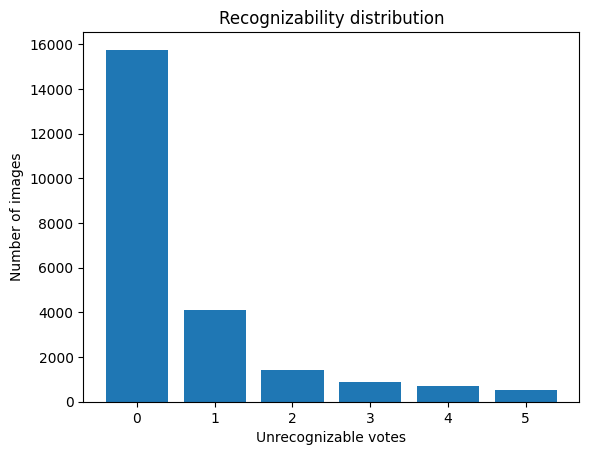

In [ ]:
#Printing data distributions for unrecognizability
votes = Counter(
    item["unrecognizable"]
    for item in train_data
)

for count in range(6):
    print(f"{count} votes: {votes[count]} images")

plt.bar(range(6), [votes[i] for i in range(6)])

plt.xlabel("Unrecognizable votes")
plt.ylabel("Number of images")
plt.title("Recognizability distribution")
plt.show()

{'FRM': 1, 'BLR': 5, 'DRK': 0, 'BRT': 3, 'OBS': 0, 'OTH': 0, 'NON': 0, 'ROT': 0}


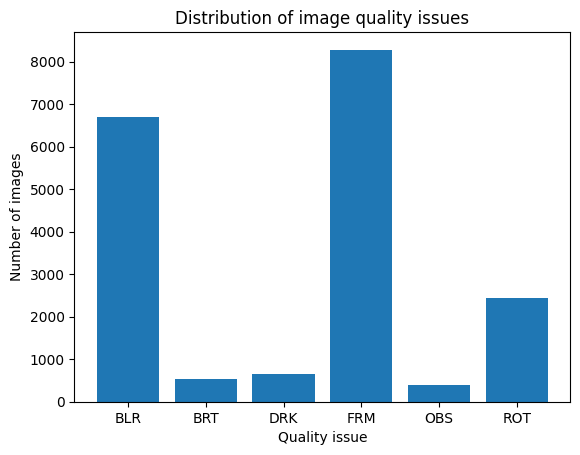

In [ ]:
#Printing specific image flaw distribution where values >= 3 means that the flaw is present
print(train_data[0]["flaws"])
flaws = ["BLR", "BRT", "DRK", "FRM", "OBS", "ROT"]

flaw_counts = {
    flaw: sum(item["flaws"][flaw] >= 3 for item in train_data)
    for flaw in flaws
}

plt.bar(flaw_counts.keys(), flaw_counts.values())
plt.xlabel("Quality issue")
plt.ylabel("Number of images")
plt.title("Distribution of image quality issues")
plt.show()